# One-class masked autoencoder (widedeep TabMlp encoder-decoder) at T = 64, 48 and 32

A masking-based autoencoder that follows pytorch-widedeep's self-supervised encoder-decoder pretraining
(`EncoderDecoderTrainer(encoder=TabMlp(...), masked_prob=0.2)`), re-implemented in plain PyTorch, trained **one-class**:
only benign windows fit the weights, benign val windows drive early stopping, the LR schedule and the alarm thresholds.
The benign windows are selected with labels (on-disk benign-only splits at T = 48 / 32; at T = 64 the label file of the
train split is read once to keep the benign windows, as in `task/encoder` mode ae); no label enters the training loss.
It runs on exactly the windows of the one-class ConvAE cells (`task/encoder` ae, `task/autoencoder_benign_t48`,
`task/autoencoder_benign_t32`), so its numbers sit next to theirs.

Three label-free scores per window, all over real cells only: **masked_recon** (each real cell hidden exactly once in
five fixed 20 % masks, error of the cell reconstructed while hidden), **full_recon** (nothing hidden) and
**mahalanobis** (distance of z to a Gaussian fitted on the benign train z).

This notebook runs from the repo root and only reads the 12 finished TabMlp runs
`task/masked_autoencoder/runs/T{64,48,32}-mlp-seed{0,1,2,3}/` written by `npm run mae:all`; it trains nothing and
re-scores nothing. Sections: 1 input, 2 model, 3 training record, 4 test results, 5 ROC curves, 6 comparison with the
one-class ConvAE, 7 analysis. Side experiment, not the thesis TimesNet model.

Setup: repo-root check, package imports, the 12 run folders (config, summary, history, test metrics).

In [1]:
import json
from pathlib import Path

assert Path("task/masked_autoencoder/config.py").is_file(), "run this notebook from the repo root"

from task.masked_autoencoder.config import PROTOCOLS, RUNS_DIR, MAEConfig
from task.masked_autoencoder.data import make_source
from task.masked_autoencoder.evaluate import load_scores
from task.masked_autoencoder.model import MaskedTabularAutoencoder, count_params
from task.masked_autoencoder.plots import PNG_NAME, LossCurvePlot

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score, roc_curve

pd.set_option("display.width", 200)
WINDOWS, SEEDS, ENCODER = (64, 48, 32), (0, 1, 2, 3), "mlp"
SCORES = ("masked_recon", "full_recon", "mahalanobis")
ATTACKS = ("GridSybil", "DataReplay", "DoSRandom", "DoSDisruptive")


def run_dir(t, seed):
    return Path(RUNS_DIR) / f"T{t}-{ENCODER}-seed{seed}"


RUNS = {}
for t in WINDOWS:
    for seed in SEEDS:
        d = run_dir(t, seed)
        r = {name: json.loads((d / f"{name}.json").read_text()) for name in ("config", "summary", "test_metrics", "env")}
        r["history"] = pd.read_json(d / "history.jsonl", lines=True)
        assert r["config"]["window"] == t and r["config"]["seed"] == seed and r["config"]["encoder"] == ENCODER
        assert r["config"]["max_windows"] == 0, "a capped quick-check run"
        assert r["summary"]["label_reads"] == ([] if t != 64 else r["summary"]["label_reads"])
        RUNS[(t, seed)] = r
print(f"{len(RUNS)} finished runs under {RUNS_DIR}:", ", ".join(run_dir(t, s).name for t, s in RUNS))

12 finished runs under task/masked_autoencoder/runs: T64-mlp-seed0, T64-mlp-seed1, T64-mlp-seed2, T64-mlp-seed3, T48-mlp-seed0, T48-mlp-seed1, T48-mlp-seed2, T48-mlp-seed3, T32-mlp-seed0, T32-mlp-seed1, T32-mlp-seed2, T32-mlp-seed3


## 1. Input

Three window sizes, each with the data protocol of its one-class ConvAE sibling (`config.PROTOCOLS`): the encoder input
folder, the sibling's decoded-shard cache, the attack test splits and the early-stopping / LR-schedule settings.

In [2]:
pd.DataFrame({t: {"data": p.data_dir, "sibling (splits, cache, protocol)": p.sibling,
                  "attack test splits": ", ".join(p.attack_splits) or "GridSybil inside `test` (mixed)",
                  "early-stop patience": p.patience, "plateau patience": p.plateau_patience,
                  "min_delta (relative)": p.min_delta} for t, p in PROTOCOLS.items()}).T

,data,"sibling (splits, cache, protocol)",attack test splits,early-stop patience,plateau patience,min_delta (relative)
64,src/data/encoder_input/benign_gridsybil/T64,task/encoder (mode ae),GridSybil inside `test` (mixed),5,3,0.0
48,src/data/encoder_input/benign_gridsybil/T48_be...,task/autoencoder_benign_t48,test_gridsybil,10,5,0.0001
32,src/data/encoder_input/all/T32_benign,task/autoencoder_benign_t32,"test_gridsybil, test_datareplay, test_dosrando...",10,5,0.0001


Window counts, sender vehicles and tracks per split, from each run's `summary.json` (fit / val) and `test_metrics.json`
(test). They are asserted equal over the four seeds (the seed changes the weights, batch order and training masks, not
the data). At T = 64 val = 10 % of the benign train sender vehicles (`VehicleSplit`, split seed 0, the `task/encoder`
draw); at T = 48 / 32 val is the on-disk val split.

In [3]:
rows = {}
for t in WINDOWS:
    per_seed = []
    for seed in SEEDS:
        s, m = RUNS[(t, seed)]["summary"], RUNS[(t, seed)]["test_metrics"]
        g = m["attacks"]["GridSybil"]
        per_seed.append({
            "train windows (benign)": s["train_windows"], "val windows (benign)": s["val_windows"],
            "train vehicles": s["train_vehicles"], "val vehicles": s["val_vehicles"], "val tracks": s["val_tracks"],
            **{f"test {k}": v for k, v in m["windows"].items() if k != "val"},
            "test vehicles": m["label_checks"]["test_vehicles"],
            "test vehicles in train / val": m["label_checks"]["test_vehicles_in_train_or_val"],
            "1-3-row share, benign test": round(g["share_rows_1_3"]["benign"], 3),
            "1-3-row share, GridSybil test": round(g["share_rows_1_3"]["attack"], 3),
        })
    assert all(p == per_seed[0] for p in per_seed), f"T{t}: data differ between seeds"
    rows[f"T = {t}"] = per_seed[0]
counts = pd.DataFrame(rows).astype(object).fillna("-")
counts

,T = 64,T = 48,T = 32
train windows (benign),107924.0,112890.0,502773.0
val windows (benign),12149.0,13584.0,65313.0
train vehicles,3263.0,3223.0,4206.0
val vehicles,362.0,402.0,524.0
val tracks,11482.0,12218.0,52108.0
test benign_test,12741.0,13405.0,60142.0
test GridSybil,25685.0,27064.0,28087.0
test vehicles,574.0,574.0,750.0
test vehicles in train / val,0.0,0.0,0.0
"1-3-row share, benign test",0.143,0.138,0.139


The **positive class** differs by T: at T = 64 and 48 the test split holds the benign and GridSybil windows of the
benign + GridSybil folders (GridSybil is the majority, chance PR-AUC ≈ 0.67); at T = 32 the benign test windows come from
all 8 folders and each of the four attacks is tested against the same benign test windows (GridSybil share ≈ 0.32).

## 2. Model

Each window (T × 13, prefix row mask) is flattened to 13 T continuous columns, and the T row-mask values are appended as
T extra input columns: **14 T inputs**. Encoder = TabMlp [14 T → 64 → 16] (Linear → ReLU → Dropout 0.1 per layer),
z = 16; decoder = the mirrored TabMlpDecoder [16 → 64] followed by a plain Linear(64, 13 T). During training every real
cell is hidden with probability 0.2 (set to 0 in the input, never a padding cell), and the loss is widedeep's
`EncoderDecoderLoss` on the hidden cells only. Layer list and parameter count per T (asserted against the runs'
`summary.json`):

In [4]:
param_rows, layer_tables = {}, {}
for t in WINDOWS:
    cfg = MAEConfig.from_dict(RUNS[(t, 0)]["config"])
    model = MaskedTabularAutoencoder(cfg).eval()
    table = []
    hooks = [m.register_forward_hook(lambda mod, inp, out, name=name: table.append(
        (name, type(mod).__name__, tuple(out.shape[1:]), sum(p.numel() for p in mod.parameters()))))
        for name, m in model.named_modules() if isinstance(m, torch.nn.Linear)]
    with torch.no_grad():
        recon, z = model(torch.zeros(2, t, 13), torch.ones(2, t, dtype=torch.bool))
    for h in hooks:
        h.remove()
    layer_tables[t] = pd.DataFrame(table, columns=["layer", "type", "output (per window)", "params"])
    params = count_params(model)
    assert all(RUNS[(t, s)]["summary"]["params"] == params for s in SEEDS)
    param_rows[f"T = {t}"] = {"input columns": 14 * t, "reconstruction": tuple(recon.shape[1:]), "z": z.shape[1],
                              "trainable parameters": params}
display(layer_tables[32].assign(note="T = 32 shown; T = 64 / 48 differ only in the 14 T / 13 T widths"))
pd.DataFrame(param_rows).T

,layer,type,output (per window),params,note
0,encoder.mlp.dense_layer_0.0,Linear,"(64,)",28736,T = 32 shown; T = 64 / 48 differ only in the 1...
1,encoder.mlp.dense_layer_1.0,Linear,"(16,)",1040,T = 32 shown; T = 64 / 48 differ only in the 1...
2,decoder.0.mlp.dense_layer_0.0,Linear,"(64,)",1088,T = 32 shown; T = 64 / 48 differ only in the 1...
3,decoder.1,Linear,"(416,)",27040,T = 32 shown; T = 64 / 48 differ only in the 1...


,input columns,reconstruction,z,trainable parameters
T = 64,896,"(64, 13)",16,113616
T = 48,672,"(48, 13)",16,85760
T = 32,448,"(32, 13)",16,57904


For scale: the one-class ConvAEs these runs are compared with have 80,189 / 71,741 / 63,293 parameters at T = 64 / 48 / 32
(package READMEs); the TabMlp has more at T = 64 / 48 and fewer at T = 32, nearly all in the first and last Linear.

**widedeep correspondence** (pytorch_widedeep 1.7.0 wheel, read only; the library is not installed):

| Here | widedeep source |
|---|---|
| `RandomObfuscator` | `models/tabular/self_supervised/_random_obfuscator.py` L14-33 |
| training / eval forward | `models/tabular/self_supervised/encoder_decoder_model.py` L60-70 (eval: mask of ones) |
| mirrored decoder | same file, L96-130 |
| `EncoderDecoderLoss` | `losses.py` L908-970 |
| `dense_layer`, `MLP` | `models/tabular/mlp/_layers.py` L7-22, L52-89 |
| TabMlp / TabMlpDecoder defaults | `models/tabular/mlp/tab_mlp.py` L158-163, L196, L223-301 |
| optimizer AdamW, train / eval step | `self_supervised_training/_base_encoder_decoder_trainer.py` L59-63; `encoder_decoder_trainer.py` L217-243 |

**Deviations from widedeep** (README):

1. The encoder sees the masked input (`feed_masked_input = True`). widedeep 1.7.0's TabMlp path computes the masked input
   but encodes the clean one (`encoder_decoder_model.py` L64-65); only its TabNet path uses the masked input.
2. The TabMlpDecoder ends in a plain Linear (`linear_mlp_output = True`); widedeep's MLP puts ReLU + dropout after the
   reconstruction layer too, which cannot output negative z-scored values.
3. Padding: flattened windows with the row mask as input columns; mask columns never hidden or reconstructed; padding
   cells never hidden, never in the loss, never scored.
4. The loss divides by the batch variance per **feature** (pooled over the batch's real cells), not per column (a late
   time step can have no real cell in a batch); identical to widedeep when T = 1.
5. Batch 256, early stopping and ReduceLROnPlateau (widedeep: batch 32, fixed epochs, no schedule), as in the sibling
   ConvAEs; validation loss = deterministic masked-reconstruction MSE.
6. Small widths with z = 16 (widedeep defaults: TabMlp [200, 100]).

## 3. Training record

Per run, from `summary.json` and `history.jsonl`: best epoch, epochs run, stop reason, LR halvings, the best benign val
masked MSE (the early-stopping quantity), the val full MSE and train loss at the best epoch, and the training time.

In [5]:
rec = []
for (t, seed), r in RUNS.items():
    s, h = r["summary"], r["history"]
    b = h.loc[h.epoch == s["best_epoch"]].iloc[0]
    rec.append({"T": t, "seed": seed, "best epoch": s["best_epoch"], "epochs run": s["epochs_run"],
                "stop": s["stop_reason"], "LR halvings": len(s["lr_changes"]),
                "first halving after epoch": s["lr_changes"][0]["after_epoch"] if s["lr_changes"] else None,
                "final LR": float(h.lr.iloc[-1]), "val masked (best)": s["best_val_loss"],
                "val full (best)": float(b.val_full_mse), "train loss (best)": float(b.train_loss),
                "val masked epoch 1": float(h.val_masked_mse.iloc[0]),
                "train min": round(s["train_seconds"] / 60, 1), "wall min": round(s["wall_seconds"] / 60, 1),
                "device": s["device"], "z dead units": s["z_dead_units_train"],
                "Mahalanobis cond": round(s["mahalanobis"]["cond"], 1)})
rec = pd.DataFrame(rec).set_index(["T", "seed"])
for (t, seed), r in RUNS.items():  # the summary's best = the history row of the best epoch
    h = r["history"].set_index("epoch")
    assert np.isclose(h.val_masked_mse.loc[r["summary"]["best_epoch"]], r["summary"]["best_val_loss"])
rec.round(4)

best epoch  epochs run            stop  LR halvings  first halving after epoch  final LR  val masked (best)  val full (best)  train loss (best)  val masked epoch 1  train min  wall min  \
T  seed                                                                                                                                                                                             
64 0             63          68  early_stopping            3                         47    0.0001             0.2917           0.2753             0.5124              0.3987        0.9       1.0   
   1             41          46  early_stopping            2                         28    0.0002             0.2926           0.2775             0.5138              0.3871        0.7       0.7   
   2             46          51  early_stopping            3                         25    0.0001             0.2910           0.2779             0.5097              0.4116        0.7       0.8   
   3             68          73  early_stopping            4                         38    0.0001             0.2913           0.2752             0.5093              0.3897        1.0       1.0   
48 0            101         111  early_stopping            5                         47    0.0000             0.3469           0.3306             0.5070              0.4316        1.6       1.7   
   1             80          90  early_stopping            5                         25    0.0000             0.3457           0.3282             0.5062              0.4299        1.3       1.3   
   2            110         120  early_stopping            5                         54    0.0000             0.3427           0.3230             0.4974              0.4269        1.7       1.7   
   3             84          94  early_stopping            3                         42    0.0001             0.3468           0.3299             0.5048              0.4131        1.3       1.3   
32 0             43          53  early_stopping            3                         30    0.0001             0.3248           0.3016             0.4829              0.3572        4.2       4.4   
   1             58          68  early_stopping            4                         32    0.0001             0.3192           0.2999             0.4811              0.3550        5.4       5.4   
   2             45          55  early_stopping            3                         29    0.0001             0.3267           0.3058             0.4832              0.3568        4.4       4.4   
   3             48          58  early_stopping            3                         26    0.0001             0.3259           0.3059             0.4892              0.3559        4.6       4.7   

        device  z dead units  Mahalanobis cond  
T  seed                                         
64 0       mps             0             206.7  
   1       mps             0              70.0  
   2       mps             0              66.7  
   3       mps             0              55.9  
48 0       mps             0             154.6  
   1       mps             0              67.8  
   2       mps             0             183.2  
   3       mps             0              66.8  
32 0       mps             0             188.4  
   1       mps             0             561.5  
   2       mps             0            1228.5  
   3       mps             0             112.5

Loss curves of all 12 runs (one row per T, one column per seed), drawn by `task.masked_autoencoder.plots` from
`history.jsonl` + `summary.json`; the same panels are saved as `<run>/loss_curve.png` (`npm run mae:plots`). Blue = the
training loss (`EncoderDecoderLoss`: hidden cells only, divided by the batch variance of each feature, averaged per
window, dropout on); orange = benign val masked-reconstruction MSE (5 fixed masks, pooled over every real cell, dropout
off; early stopping and the LR schedule follow it); green dashed = val full-reconstruction MSE; red = best epoch;
grey dotted = LR halved; purple = LR (right axis). The training loss and the val MSEs are **different quantities**, so
their vertical gap is not a generalisation gap. In short: **training minimises the variance-normalised loss; early
stopping, the LR schedule and all three test scores use the plain MSE on the z-scored features.**

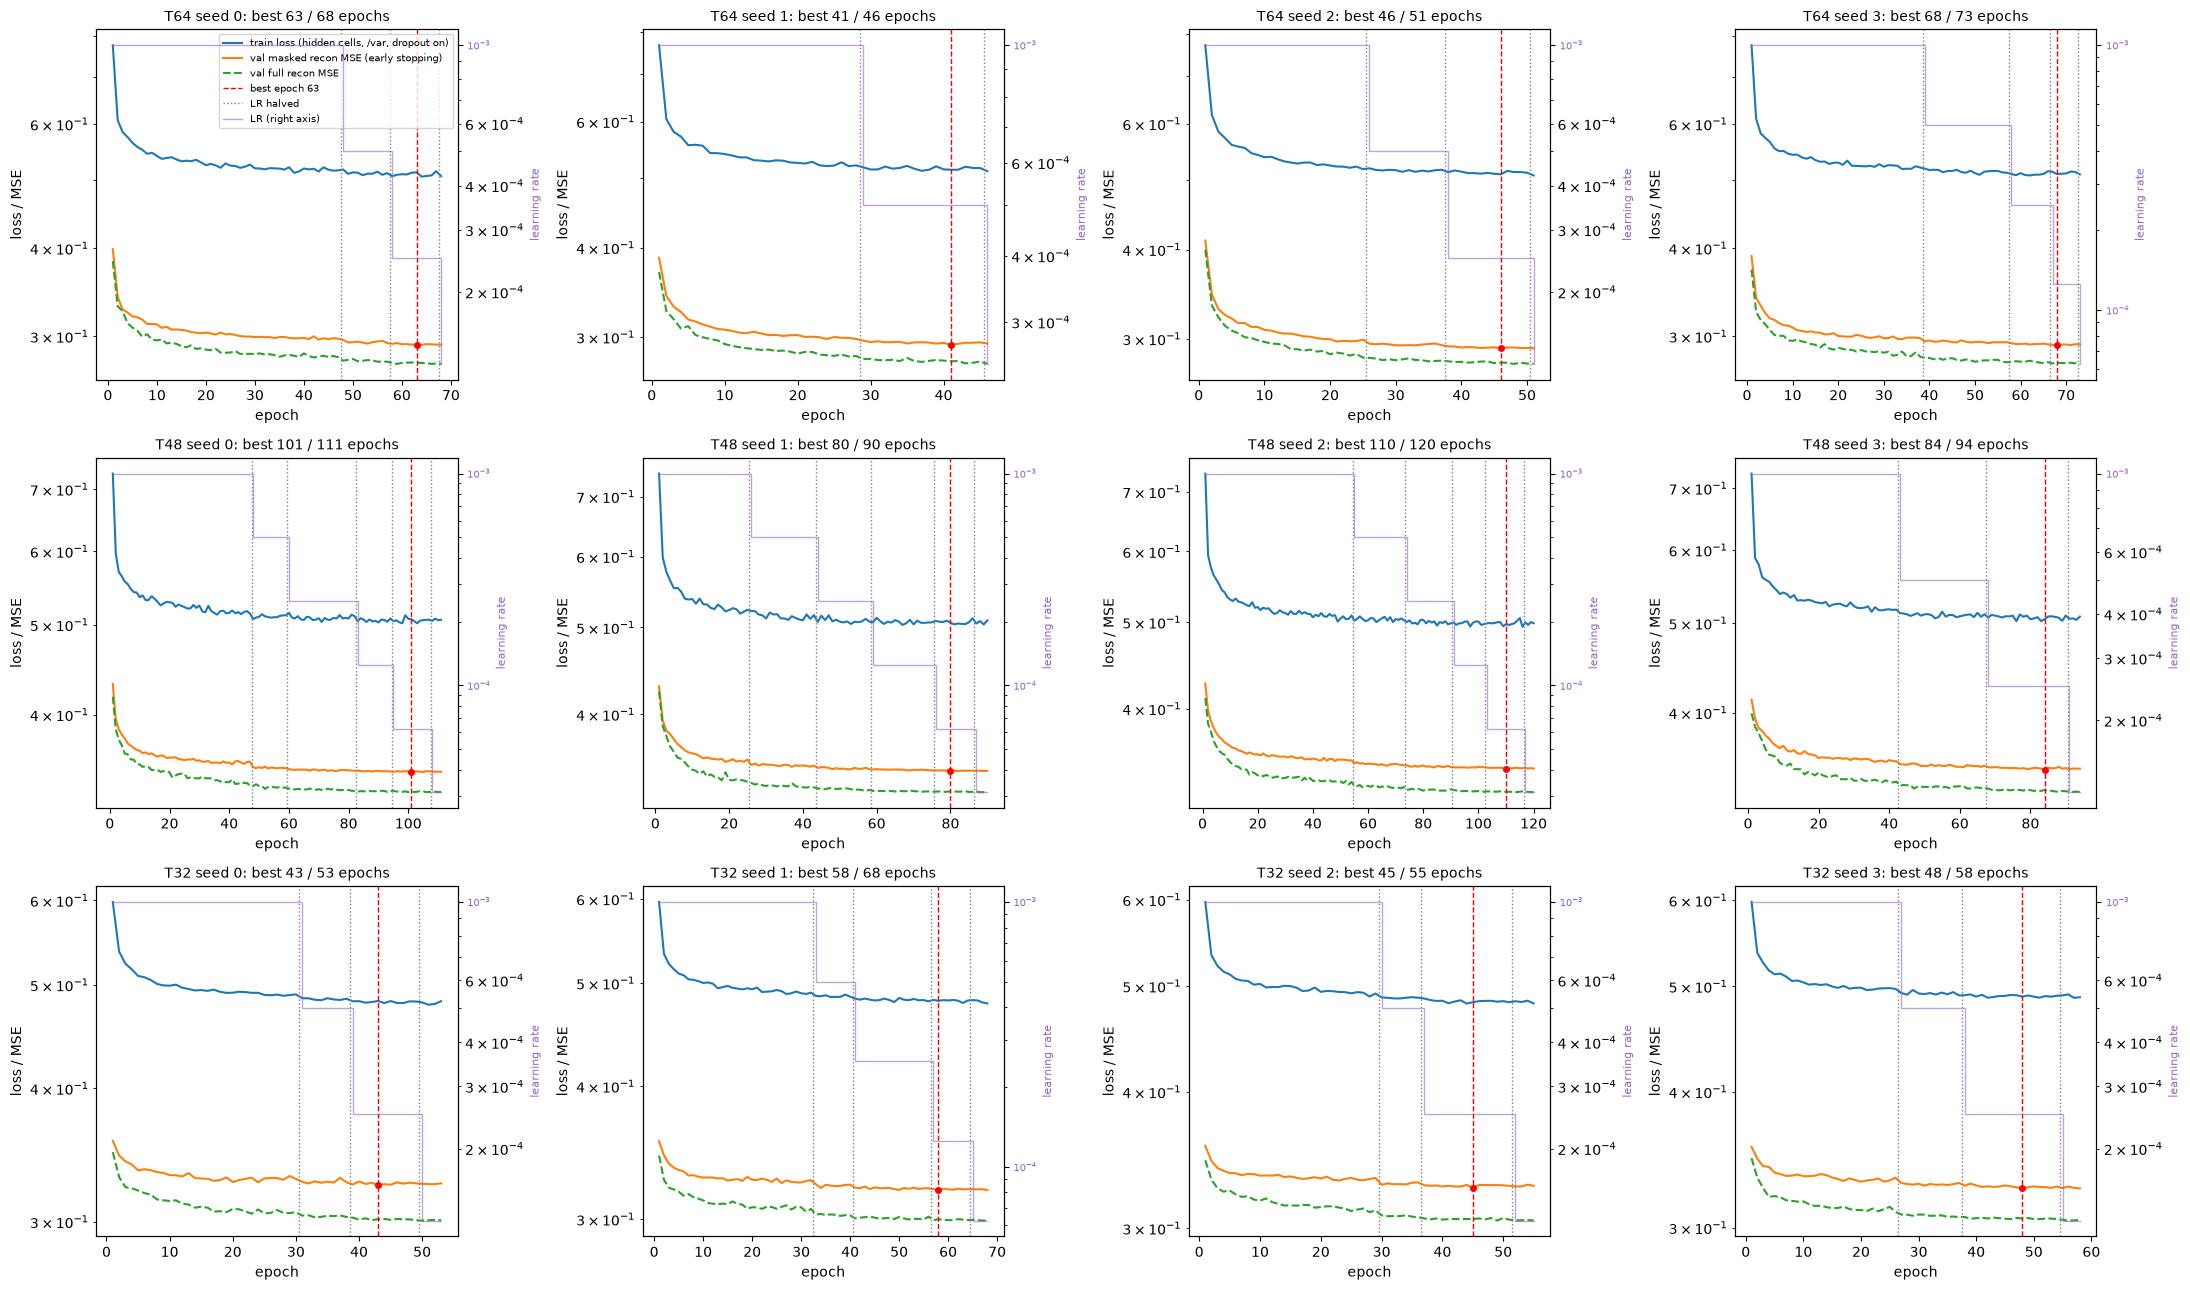

saved PNGs:
  task/masked_autoencoder/runs/T64-mlp-seed0/loss_curve.png
  task/masked_autoencoder/runs/T64-mlp-seed1/loss_curve.png
  task/masked_autoencoder/runs/T64-mlp-seed2/loss_curve.png
  task/masked_autoencoder/runs/T64-mlp-seed3/loss_curve.png
  task/masked_autoencoder/runs/T48-mlp-seed0/loss_curve.png
  task/masked_autoencoder/runs/T48-mlp-seed1/loss_curve.png
  task/masked_autoencoder/runs/T48-mlp-seed2/loss_curve.png
  task/masked_autoencoder/runs/T48-mlp-seed3/loss_curve.png
  task/masked_autoencoder/runs/T32-mlp-seed0/loss_curve.png
  task/masked_autoencoder/runs/T32-mlp-seed1/loss_curve.png
  task/masked_autoencoder/runs/T32-mlp-seed2/loss_curve.png
  task/masked_autoencoder/runs/T32-mlp-seed3/loss_curve.png


In [6]:
fig, axes = plt.subplots(len(WINDOWS), len(SEEDS), figsize=(22, 13))
for i, t in enumerate(WINDOWS):
    for j, seed in enumerate(SEEDS):
        plot = LossCurvePlot(run_dir(t, seed))
        plot.draw(axes[i, j], legend=(i == 0 and j == 0))
        axes[i, j].set_title(f"T{t} seed {seed}: best {plot.history.best_epoch} / "
                             f"{plot.history.summary['epochs_run']} epochs", fontsize=10)
        assert (run_dir(t, seed) / PNG_NAME).is_file(), "npm run mae:plots"
fig.tight_layout(); plt.show()
print("saved PNGs:", *(str(run_dir(t, s) / PNG_NAME) for t in WINDOWS for s in SEEDS), sep="\n  ")

How the val curve moved: share of the total decrease of the val masked MSE (epoch 1 → best) already reached at epoch 10,
the relative gain from epoch 10 to the best epoch, the relative gain after the first LR halving, and the train / val
ratio at the best epoch (both curves fall together; the ratio says only how the two quantities scale).

In [7]:
shape = []
for (t, seed), r in RUNS.items():
    h, s = r["history"].set_index("epoch"), r["summary"]
    v1, vb, v10 = h.val_masked_mse.iloc[0], s["best_val_loss"], h.val_masked_mse.loc[10]
    first = s["lr_changes"][0]["after_epoch"] if s["lr_changes"] else None
    v_first = h.val_masked_mse.loc[first] if first else np.nan
    shape.append({"T": t, "seed": seed, "share of decrease by epoch 10": (v1 - v10) / (v1 - vb),
                  "rel. gain epoch 10 -> best": (v10 - vb) / v10,
                  "rel. gain after first LR halving": (v_first - vb) / v_first,
                  "train / val masked at best": h.train_loss.loc[s["best_epoch"]] / vb,
                  "val full / val masked at best": h.val_full_mse.loc[s["best_epoch"]] / vb,
                  "epochs best -> stop": s["epochs_run"] - s["best_epoch"]})
shape = pd.DataFrame(shape).set_index(["T", "seed"])
shape.round(3)

share of decrease by epoch 10  rel. gain epoch 10 -> best  rel. gain after first LR halving  train / val masked at best  val full / val masked at best  epochs best -> stop
T  seed                                                                                                                                                                             
64 0                             0.811                       0.065                             0.020                       1.757                          0.944                    5
   1                             0.846                       0.047                             0.018                       1.756                          0.948                    5
   2                             0.853                       0.057                             0.027                       1.752                          0.955                    5
   3                             0.824                       0.056                             0.023                       1.749                          0.945                    5
48 0                             0.779                       0.051                             0.025                       1.461                          0.953                   10
   1                             0.808                       0.045                             0.029                       1.464                          0.949                   10
   2                             0.756                       0.057                             0.021                       1.451                          0.942                   10
   3                             0.677                       0.058                             0.021                       1.456                          0.951                   10
32 0                             0.785                       0.021                             0.013                       1.487                          0.929                   10
   1                             0.749                       0.027                             0.022                       1.507                          0.939                   10
   2                             0.721                       0.025                             0.020                       1.479                          0.936                   10
   3                             0.713                       0.026                             0.023                       1.501                          0.939                   10

## 4. Test results

From each run's `test_metrics.json`, written by `evaluate.py` (every val and test window scored and saved before any
label was read; thresholds = benign val p95 / p99 from `summary.json`). Each attack is compared with the benign test
windows of the same test vehicles; the **length-only** reference is the fixed rule score = −real messages per window.
Mean ± sample sd over seeds 0–3 (n = 4).

In [8]:
rows = []
for (t, seed), r in RUNS.items():
    for attack, m in r["test_metrics"]["attacks"].items():
        for name in SCORES:
            w = m["window"][name]
            rows.append({"T": t, "seed": seed, "attack": attack, "score": name, "AUROC": w["auroc"],
                         "PR-AUC": w["pr_auc"], "chance": w["chance"], "AUROC 1-3 rows": w["rows_1_3"]["auroc"],
                         "AUROC >= 4 rows": w["rows_ge_4"]["auroc"],
                         "n attack 1-3 rows": w["rows_1_3"]["n_attack"], "n attack >= 4 rows": w["rows_ge_4"]["n_attack"],
                         "n benign >= 4 rows": w["rows_ge_4"]["n_benign"], "recall p95": w["recall_p95"],
                         "benign FPR p95": w["benign_fpr_p95"], "recall p99": w["recall_p99"],
                         "benign FPR p99": w["benign_fpr_p99"],
                         "track max AUROC": m["track"][f"{name}_max"]["auroc"],
                         "track mean AUROC": m["track"][f"{name}_mean"]["auroc"]})
        L = m["length_only"]
        rows.append({"T": t, "seed": seed, "attack": attack, "score": "length only", "AUROC": L["auroc"],
                     "PR-AUC": L["pr_auc"], "chance": L["chance"]})
res = pd.DataFrame(rows)
SCORE_ORDER = [*SCORES, "length only"]


def mean_sd(df, keys, cols, digits=3):
    # "mean ± sd" strings over seeds (sample sd, ddof 1); asserts 4 seeds per cell.
    g = df.groupby(keys, sort=False)[cols]
    assert (g.size() == len(SEEDS)).all()
    mu, sd = g.mean(), g.std(ddof=1)
    return mu.round(digits).astype(str) + " ± " + sd.round(digits).astype(str), mu, sd


print(f"{len(res)} rows: {res["T"].nunique()} window sizes x {res.seed.nunique()} seeds x scores x attacks")

96 rows: 3 window sizes x 4 seeds x scores x attacks


**GridSybil vs benign test**, window AUROC per T (rows = score, columns = T); PR-AUC with its chance level below.

In [9]:
grid = res[res.attack == "GridSybil"]
txt, mu_auroc, sd_auroc = mean_sd(grid, ["score", "T"], ["AUROC"])
gs_table = txt["AUROC"].unstack("T").loc[SCORE_ORDER, list(WINDOWS)]
gs_table.columns = [f"T = {t}" for t in WINDOWS]
display(gs_table)
txt_pr, _, _ = mean_sd(grid, ["score", "T"], ["PR-AUC", "chance"])
pr = txt_pr["PR-AUC"].unstack("T").loc[SCORE_ORDER, list(WINDOWS)]
pr.loc["chance (attack share)"] = grid.groupby("T").chance.first().loc[list(WINDOWS)].round(3).astype(str).values
pr.columns = [f"T = {t}" for t in WINDOWS]
pr

,T = 64,T = 48,T = 32
score,,,
masked_recon,0.531 ± 0.002,0.607 ± 0.001,0.657 ± 0.002
full_recon,0.539 ± 0.003,0.603 ± 0.002,0.65 ± 0.003
mahalanobis,0.398 ± 0.018,0.403 ± 0.016,0.408 ± 0.017
length only,0.535 ± 0.0,0.53 ± 0.0,0.559 ± 0.0


,T = 64,T = 48,T = 32
score,,,
masked_recon,0.707 ± 0.001,0.773 ± 0.001,0.514 ± 0.001
full_recon,0.722 ± 0.001,0.772 ± 0.001,0.515 ± 0.001
mahalanobis,0.634 ± 0.012,0.641 ± 0.009,0.316 ± 0.014
length only,0.699 ± 0.0,0.697 ± 0.0,0.367 ± 0.0
chance (attack share),0.668,0.669,0.318


Per seed, GridSybil window AUROC (the spread behind the ± above).

In [10]:
grid.pivot_table(index=["T", "score"], columns="seed", values="AUROC", sort=False).loc[list(WINDOWS)].round(4)

seed                  0       1       2       3
T  score                                       
64 masked_recon  0.5329  0.5316  0.5285  0.5311
   full_recon    0.5400  0.5407  0.5342  0.5402
   mahalanobis   0.3774  0.4129  0.4128  0.3893
   length only   0.5348  0.5348  0.5348  0.5348
48 masked_recon  0.6060  0.6073  0.6089  0.6072
   full_recon    0.6006  0.6034  0.6048  0.6014
   mahalanobis   0.4204  0.3846  0.4105  0.3948
   length only   0.5304  0.5304  0.5304  0.5304
32 masked_recon  0.6556  0.6589  0.6567  0.6552
   full_recon    0.6479  0.6545  0.6511  0.6474
   mahalanobis   0.3957  0.3912  0.4219  0.4241
   length only   0.5586  0.5586  0.5586  0.5586

**T = 32, all four attacks** vs the same benign test windows (window AUROC, mean ± sd over seeds). DataReplay and DoS
windows are mostly 1–3 rows long (F11), so length alone already separates them.

In [11]:
t32 = res[res["T"] == 32]
txt, _, _ = mean_sd(t32, ["score", "attack"], ["AUROC"])
t32_table = txt["AUROC"].unstack("attack").loc[SCORE_ORDER, list(ATTACKS)]
display(t32_table)
share = {a: RUNS[(32, 0)]["test_metrics"]["attacks"][a]["share_rows_1_3"]["attack"] for a in ATTACKS}
share["benign test"] = RUNS[(32, 0)]["test_metrics"]["attacks"]["GridSybil"]["share_rows_1_3"]["benign"]
pd.Series(share, name="share of 1-3-row windows").round(3).to_frame().T

attack,GridSybil,DataReplay,DoSRandom,DoSDisruptive
score,,,,
masked_recon,0.657 ± 0.002,0.693 ± 0.003,0.988 ± 0.001,0.851 ± 0.006
full_recon,0.65 ± 0.003,0.54 ± 0.01,0.976 ± 0.002,0.732 ± 0.007
mahalanobis,0.408 ± 0.017,0.269 ± 0.036,0.394 ± 0.073,0.222 ± 0.032
length only,0.559 ± 0.0,0.952 ± 0.0,0.967 ± 0.0,0.967 ± 0.0


,GridSybil,DataReplay,DoSRandom,DoSDisruptive,benign test
share of 1-3-row windows,0.204,0.949,0.997,0.997,0.139


**Short vs long windows**: window AUROC on the windows with 1–3 real rows only and on those with ≥ 4 rows only (both
classes restricted), GridSybil at every T and the four attacks at T = 32.

In [12]:
sub = res[(res.score != "length only") & ((res.attack == "GridSybil") | (res["T"] == 32))].copy()
sub["case"] = "T" + sub["T"].astype(str) + " " + sub["attack"]
txt, _, _ = mean_sd(sub, ["case", "score"], ["AUROC", "AUROC 1-3 rows", "AUROC >= 4 rows"])
n_cols = sub.groupby(["case", "score"], sort=False)[["n attack 1-3 rows", "n attack >= 4 rows", "n benign >= 4 rows"]].first()
txt.join(n_cols.astype(int))

AUROC AUROC 1-3 rows AUROC >= 4 rows  n attack 1-3 rows  n attack >= 4 rows  n benign >= 4 rows
case              score                                                                                                                
T64 GridSybil     masked_recon  0.531 ± 0.002  0.398 ± 0.003    0.55 ± 0.002               4898               20787               10919
                  full_recon    0.539 ± 0.003  0.448 ± 0.007   0.558 ± 0.002               4898               20787               10919
                  mahalanobis   0.398 ± 0.018  0.374 ± 0.031   0.412 ± 0.023               4898               20787               10919
T48 GridSybil     masked_recon  0.607 ± 0.001  0.499 ± 0.003   0.619 ± 0.001               5003               22061               11559
                  full_recon    0.603 ± 0.002  0.526 ± 0.004   0.618 ± 0.002               5003               22061               11559
                  mahalanobis   0.403 ± 0.016  0.382 ± 0.029   0.414 ± 0.017               5003               22061               11559
T32 GridSybil     masked_recon  0.657 ± 0.002  0.529 ± 0.001   0.674 ± 0.002               5722               22365               51773
                  full_recon     0.65 ± 0.003  0.563 ± 0.008   0.669 ± 0.003               5722               22365               51773
                  mahalanobis   0.408 ± 0.017  0.373 ± 0.019    0.424 ± 0.02               5722               22365               51773
T32 DataReplay    masked_recon  0.693 ± 0.003  0.557 ± 0.006   0.359 ± 0.004              72400                3883               51773
                  full_recon      0.54 ± 0.01  0.521 ± 0.009   0.301 ± 0.002              72400                3883               51773
                  mahalanobis   0.269 ± 0.036  0.327 ± 0.014   0.415 ± 0.014              72400                3883               51773
T32 DoSRandom     masked_recon  0.988 ± 0.001  0.969 ± 0.001       1.0 ± 0.0             199311                 523               51773
                  full_recon    0.976 ± 0.002  0.959 ± 0.003       1.0 ± 0.0             199311                 523               51773
                  mahalanobis   0.394 ± 0.073   0.472 ± 0.11   0.715 ± 0.172             199311                 523               51773
T32 DoSDisruptive masked_recon  0.851 ± 0.006  0.746 ± 0.007       1.0 ± 0.0             199302                 524               51773
                  full_recon    0.732 ± 0.007  0.704 ± 0.004       1.0 ± 0.0             199302                 524               51773
                  mahalanobis   0.222 ± 0.032  0.288 ± 0.043    0.269 ± 0.05             199302                 524               51773

The window counts are the same in every seed. At T = 32 the ≥ 4-row subsets of DoSRandom and DoSDisruptive hold only a
few hundred attack windows (column `n attack >= 4 rows`), so an AUROC near 1.000 there rests on a small sample.

**Alarms at the benign val thresholds**: attack recall and benign-test FPR at val p95 and p99 (window level). On benign
data from the val distribution the FPR would be 0.05 / 0.01.

In [13]:
txt, _, _ = mean_sd(sub, ["case", "score"], ["recall p95", "benign FPR p95", "recall p99", "benign FPR p99"])
txt

recall p95 benign FPR p95     recall p99 benign FPR p99
case              score                                                                   
T64 GridSybil     masked_recon  0.093 ± 0.001  0.048 ± 0.001  0.027 ± 0.001     0.01 ± 0.0
                  full_recon    0.112 ± 0.001  0.047 ± 0.001  0.051 ± 0.001  0.011 ± 0.001
                  mahalanobis   0.065 ± 0.006  0.055 ± 0.004  0.038 ± 0.005  0.011 ± 0.001
T48 GridSybil     masked_recon  0.172 ± 0.001  0.045 ± 0.001    0.076 ± 0.0    0.008 ± 0.0
                  full_recon    0.174 ± 0.001  0.045 ± 0.001  0.084 ± 0.001    0.009 ± 0.0
                  mahalanobis    0.072 ± 0.01  0.052 ± 0.003  0.038 ± 0.007  0.009 ± 0.001
T32 GridSybil     masked_recon     0.21 ± 0.0    0.052 ± 0.0  0.087 ± 0.002    0.009 ± 0.0
                  full_recon    0.214 ± 0.001    0.051 ± 0.0  0.094 ± 0.002    0.008 ± 0.0
                  mahalanobis    0.077 ± 0.01  0.053 ± 0.002  0.048 ± 0.006  0.011 ± 0.001
T32 DataReplay    masked_recon  0.137 ± 0.001    0.052 ± 0.0  0.055 ± 0.002    0.009 ± 0.0
                  full_recon    0.091 ± 0.004    0.051 ± 0.0  0.034 ± 0.001    0.008 ± 0.0
                  mahalanobis   0.009 ± 0.002  0.053 ± 0.002    0.002 ± 0.0  0.011 ± 0.001
T32 DoSRandom     masked_recon  0.942 ± 0.003    0.052 ± 0.0  0.807 ± 0.006    0.009 ± 0.0
                  full_recon    0.884 ± 0.012    0.051 ± 0.0  0.691 ± 0.015    0.008 ± 0.0
                  mahalanobis    0.02 ± 0.021  0.053 ± 0.002  0.002 ± 0.003  0.011 ± 0.001
T32 DoSDisruptive masked_recon  0.448 ± 0.011    0.052 ± 0.0  0.318 ± 0.011    0.009 ± 0.0
                  full_recon    0.367 ± 0.005    0.051 ± 0.0  0.252 ± 0.006    0.008 ± 0.0
                  mahalanobis   0.002 ± 0.001  0.053 ± 0.002      0.0 ± 0.0  0.011 ± 0.001

Per track (max / mean of a link's windows), window AUROC for comparison.

In [14]:
txt, _, _ = mean_sd(sub, ["case", "score"], ["AUROC", "track max AUROC", "track mean AUROC"])
txt

AUROC track max AUROC track mean AUROC
case              score                                                       
T64 GridSybil     masked_recon  0.531 ± 0.002   0.521 ± 0.002    0.522 ± 0.002
                  full_recon    0.539 ± 0.003   0.529 ± 0.003     0.53 ± 0.003
                  mahalanobis   0.398 ± 0.018   0.385 ± 0.017    0.385 ± 0.017
T48 GridSybil     masked_recon  0.607 ± 0.001   0.594 ± 0.001    0.595 ± 0.001
                  full_recon    0.603 ± 0.002   0.589 ± 0.002     0.59 ± 0.002
                  mahalanobis   0.403 ± 0.016   0.385 ± 0.016    0.383 ± 0.017
T32 GridSybil     masked_recon  0.657 ± 0.002    0.63 ± 0.002    0.638 ± 0.002
                  full_recon     0.65 ± 0.003   0.623 ± 0.004     0.63 ± 0.004
                  mahalanobis   0.408 ± 0.017    0.382 ± 0.02     0.382 ± 0.02
T32 DataReplay    masked_recon  0.693 ± 0.003   0.651 ± 0.003    0.673 ± 0.003
                  full_recon      0.54 ± 0.01    0.495 ± 0.01     0.517 ± 0.01
                  mahalanobis   0.269 ± 0.036   0.247 ± 0.029    0.262 ± 0.032
T32 DoSRandom     masked_recon  0.988 ± 0.001   0.985 ± 0.001    0.987 ± 0.001
                  full_recon    0.976 ± 0.002   0.971 ± 0.003    0.974 ± 0.003
                  mahalanobis   0.394 ± 0.073   0.368 ± 0.077     0.391 ± 0.08
T32 DoSDisruptive masked_recon  0.851 ± 0.006   0.825 ± 0.006     0.84 ± 0.006
                  full_recon    0.732 ± 0.007   0.701 ± 0.007    0.717 ± 0.007
                  mahalanobis   0.222 ± 0.032     0.2 ± 0.026    0.214 ± 0.028

## 5. ROC curves from the saved score files

ROC curves are recomputed from `scores/<split>.npz` (written before labels were read). At T = 48 / 32 the class is the
split (benign `test` vs `test_<attack>`); at T = 64 the `test` split is mixed, so its label file is read here through the
package's `T64Source` (the read is logged on that source object) and aligned by window id. Each recomputed AUROC is
asserted equal to `test_metrics.json`.

In [15]:
def roc_data(t, seed, attack):
    # (labels, {score: values}, n_messages) for one attack vs benign test, from the score files only.
    folder = run_dir(t, seed) / "scores"
    if t == 64:
        test = load_scores(folder, "test")
        y = (T64_CODES != 0).astype(int)
        return y, test.scores, test.n_messages
    b = load_scores(folder, "test")
    a = load_scores(folder, f"test_{attack.lower()}")
    y = np.r_[np.zeros(len(b), int), np.ones(len(a), int)]
    return y, {k: np.r_[b.scores[k], a.scores[k]] for k in SCORES}, np.r_[b.n_messages, a.n_messages]


src64 = make_source(MAEConfig.from_dict(RUNS[(64, 0)]["config"]))
T64_CODES = src64.labels("test", "masked_autoencoder notebook: ROC curves from the saved T64 score files")
ids64 = src64.load("test").ids
for seed in SEEDS:
    assert np.array_equal(load_scores(run_dir(64, seed) / "scores", "test").ids, ids64), "T64 ids not aligned"
assert set(np.unique(T64_CODES)) <= {0, 16}
print("T64 test labels read:", src64.label_reads, "| windows", len(T64_CODES), "GridSybil", int((T64_CODES == 16).sum()))

checked = 0
for (t, seed), r in RUNS.items():
    for attack in r["test_metrics"]["attacks"]:
        y, s, n = roc_data(t, seed, attack)
        for name in SCORES:
            ref = r["test_metrics"]["attacks"][attack]["window"][name]["auroc"]
            assert abs(roc_auc_score(y, s[name]) - ref) < 1e-6, (t, seed, attack, name)
            checked += 1
        assert abs(roc_auc_score(y, -n.astype(float)) - r["test_metrics"]["attacks"][attack]["length_only"]["auroc"]) < 1e-6
print(f"{checked} AUROCs recomputed from the score files = test_metrics.json")

T64 test labels read: ['test: masked_autoencoder notebook: ROC curves from the saved T64 score files'] | windows 38426 GridSybil 25685


72 AUROCs recomputed from the score files = test_metrics.json


GridSybil vs benign test per T: the three scores and the length-only rule, all four seeds (thin lines; the AUROC in the
legend is the mean over seeds).

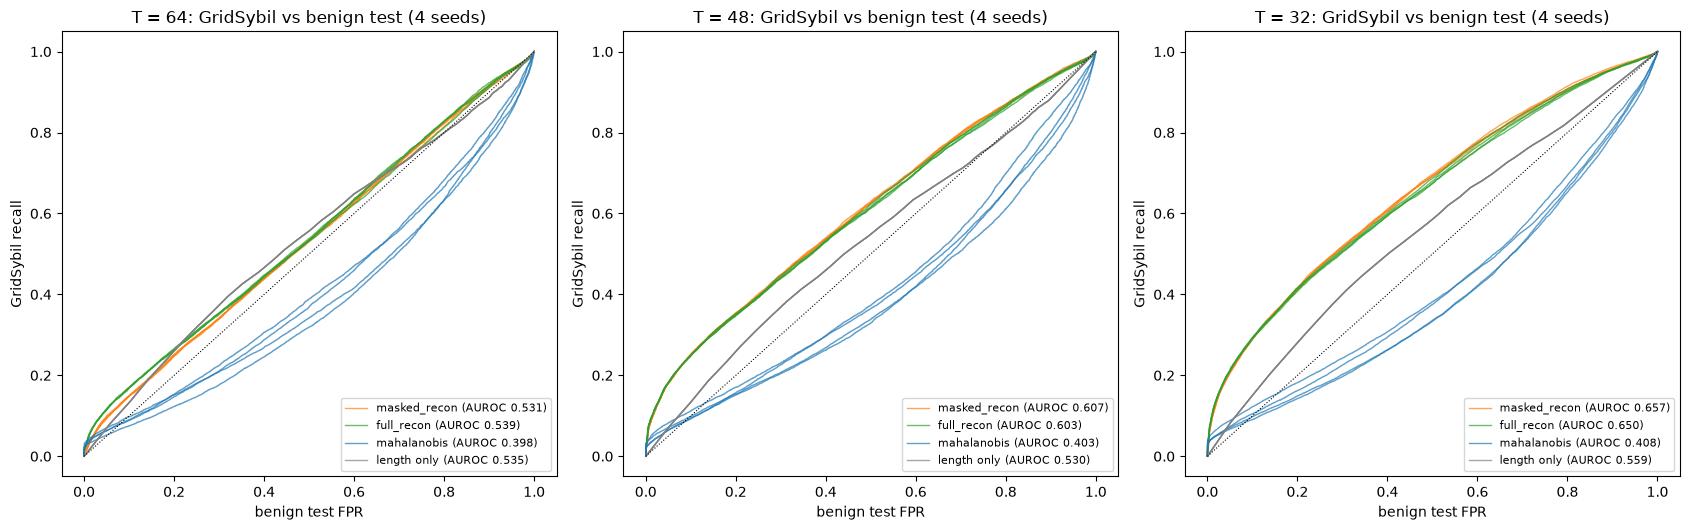

In [16]:
colors = {"masked_recon": "tab:orange", "full_recon": "tab:green", "mahalanobis": "tab:blue", "length only": "grey"}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
for ax, t in zip(axes, WINDOWS):
    for name in SCORE_ORDER:
        aucs = []
        for k, seed in enumerate(SEEDS):
            y, s, n = roc_data(t, seed, "GridSybil")
            v = -n.astype(float) if name == "length only" else s[name]
            fpr, tpr, _ = roc_curve(y, v)
            aucs.append(roc_auc_score(y, v))
            ax.plot(fpr, tpr, color=colors[name], lw=1, alpha=0.7,
                    label=f"{name} (AUROC {np.mean(aucs if k else [aucs[0]]):.3f})" if k == len(SEEDS) - 1 else None)
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.set_title(f"T = {t}: GridSybil vs benign test (4 seeds)"); ax.set_xlabel("benign test FPR")
    ax.set_ylabel("GridSybil recall"); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()

T = 32, the four attacks vs benign test (seed 0, three scores + length only).

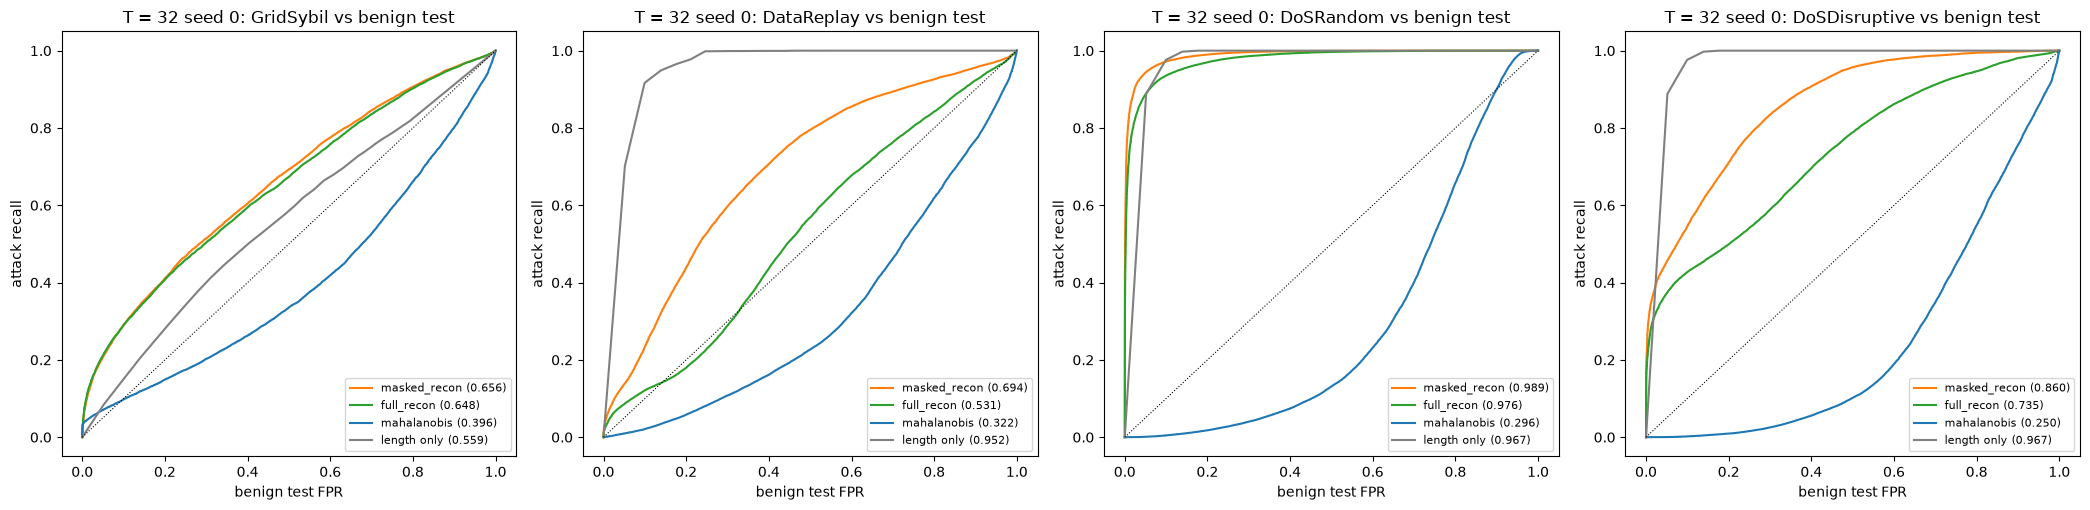

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(21, 5.2))
for ax, attack in zip(axes, ATTACKS):
    y, s, n = roc_data(32, 0, attack)
    for name in SCORE_ORDER:
        v = -n.astype(float) if name == "length only" else s[name]
        fpr, tpr, _ = roc_curve(y, v)
        ax.plot(fpr, tpr, color=colors[name], label=f"{name} ({roc_auc_score(y, v):.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.set_title(f"T = 32 seed 0: {attack} vs benign test"); ax.set_xlabel("benign test FPR")
    ax.set_ylabel("attack recall"); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()

Score distributions, GridSybil vs benign test, seed 0 per T, with the benign val p95 threshold.

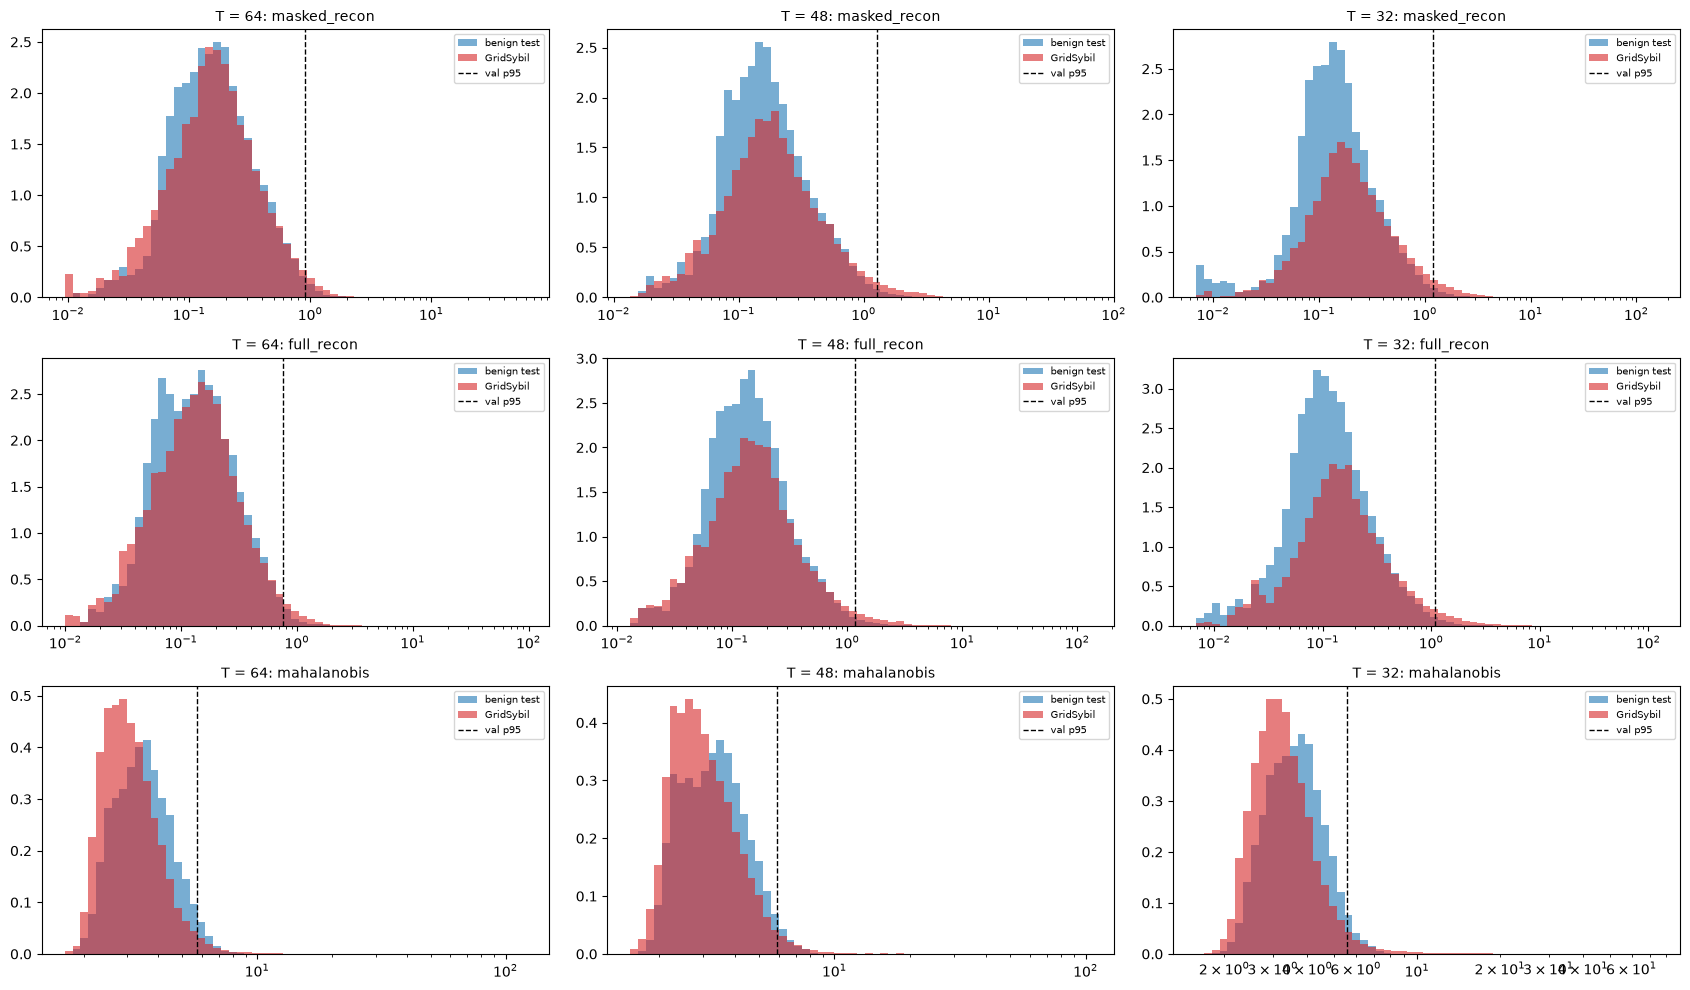

In [18]:
fig, axes = plt.subplots(len(SCORES), len(WINDOWS), figsize=(17, 10))
for j, t in enumerate(WINDOWS):
    y, s, _ = roc_data(t, 0, "GridSybil")
    thr = RUNS[(t, 0)]["summary"]["thresholds"]["window"]
    for i, name in enumerate(SCORES):
        ax, v = axes[i, j], s[name]
        bins = np.logspace(np.log10(max(v.min(), 1e-4)), np.log10(v.max()), 60)
        ax.hist(v[y == 0], bins=bins, density=True, alpha=0.6, label="benign test")
        ax.hist(v[y == 1], bins=bins, density=True, alpha=0.6, color="tab:red", label="GridSybil")
        ax.axvline(thr[name]["p95"], color="black", ls="--", lw=1, label="val p95")
        ax.set_xscale("log"); ax.set_title(f"T = {t}: {name}", fontsize=10); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

### 5b. Window length inside the scores

Short windows are harder to reconstruct while hidden: a 1-row window has no time neighbours, so `masked_recon` must
rebuild a hidden cell from the 12 other features of the same message only. Two checks from the score files, on the
**benign test windows alone** (no attack involved): the median score by real rows per window (T = 32 seed 0), and the
AUROC of each score for separating 1–3-row from longer benign windows (mean over seeds). An AUROC well above 0.5 means
the score partly measures window length.

In [19]:
y, s, n = roc_data(32, 0, "GridSybil")
ben = y == 0
med = pd.DataFrame({name: pd.Series(s[name][ben]).groupby(n[ben]).median() for name in SCORES})
med["benign windows"] = pd.Series(n[ben]).value_counts().sort_index()
display(med.loc[[1, 2, 3, 4, 8, 16, 32]].round(3).rename_axis("real rows (T32 seed 0, benign test)"))
rows = []
for (t, seed) in RUNS:
    y, s, n = roc_data(t, seed, "GridSybil")
    ben = y == 0
    short = (n[ben] <= 3).astype(int)
    rows.append({"T": t, "seed": seed, **{name: roc_auc_score(short, s[name][ben]) for name in SCORES}})
txt, _, _ = mean_sd(pd.DataFrame(rows), ["T"], list(SCORES))
txt.rename_axis("benign test only: AUROC of 1-3 rows vs >= 4 rows")

,masked_recon,full_recon,mahalanobis,benign windows
"real rows (T32 seed 0, benign test)",,,,
1,0.635,0.292,3.183,3107
2,0.351,0.187,4.062,2869
3,0.315,0.231,4.043,2393
4,0.386,0.299,3.848,2254
8,0.387,0.352,3.865,1874
16,0.277,0.252,3.893,1320
32,0.186,0.174,3.836,12540


,masked_recon,full_recon,mahalanobis
benign test only: AUROC of 1-3 rows vs >= 4 rows,,,
64,0.712 ± 0.009,0.545 ± 0.009,0.286 ± 0.026
48,0.698 ± 0.004,0.537 ± 0.007,0.3 ± 0.025
32,0.688 ± 0.004,0.541 ± 0.011,0.413 ± 0.045


**Length-matched AUROC**: the AUROC is computed separately inside every exact window length (real rows 1, 2, …, T) that
holds both benign and attack windows, and averaged with weights = attack windows at that length. Attack windows can
then no longer be told apart by being shorter than benign ones. `covered` = share of the attack windows whose length
also occurs among the benign test windows. Mean ± sd over seeds, next to the pooled AUROC and length only.

In [20]:
def length_matched_auroc(y, v, n):
    # attack-count-weighted mean of the AUROC within each exact length holding both classes; (auroc, covered share).
    aucs, weights = [], []
    for k in np.unique(n[y == 1]):
        sel = n == k
        if 0 < y[sel].sum() < sel.sum():
            aucs.append(roc_auc_score(y[sel], v[sel]))
            weights.append(y[sel].sum())
    return float(np.average(aucs, weights=weights)), float(np.sum(weights) / (y == 1).sum())


rows = []
for (t, seed), r in RUNS.items():
    for attack in r["test_metrics"]["attacks"]:
        y, s, n = roc_data(t, seed, attack)
        for name in SCORES:
            lm, cov = length_matched_auroc(y, s[name], n)
            rows.append({"T": t, "seed": seed, "attack": attack, "score": name, "pooled AUROC": roc_auc_score(y, s[name]),
                         "length-matched AUROC": lm, "covered": cov})
lm = pd.DataFrame(rows)
lm["case"] = "T" + lm["T"].astype(str) + " " + lm["attack"]
txt, mu_lm, _ = mean_sd(lm, ["case", "score"], ["pooled AUROC", "length-matched AUROC", "covered"])
length_only = res[res.score == "length only"].assign(case=lambda d: "T" + d["T"].astype(str) + " " + d["attack"])
txt = txt.join(length_only.groupby("case").AUROC.mean().round(3).rename("length only"), on="case")
txt

pooled AUROC length-matched AUROC    covered  length only
case              score                                                                   
T64 GridSybil     masked_recon  0.531 ± 0.002         0.51 ± 0.002  1.0 ± 0.0        0.535
                  full_recon    0.539 ± 0.003         0.53 ± 0.003  1.0 ± 0.0        0.535
                  mahalanobis   0.398 ± 0.018        0.403 ± 0.019  1.0 ± 0.0        0.535
T48 GridSybil     masked_recon  0.607 ± 0.001        0.589 ± 0.001  1.0 ± 0.0        0.530
                  full_recon    0.603 ± 0.002        0.595 ± 0.002  1.0 ± 0.0        0.530
                  mahalanobis   0.403 ± 0.016        0.408 ± 0.019  1.0 ± 0.0        0.530
T32 GridSybil     masked_recon  0.657 ± 0.002        0.631 ± 0.001  1.0 ± 0.0        0.559
                  full_recon     0.65 ± 0.003        0.638 ± 0.003  1.0 ± 0.0        0.559
                  mahalanobis   0.408 ± 0.017        0.415 ± 0.019  1.0 ± 0.0        0.559
T32 DataReplay    masked_recon  0.693 ± 0.003         0.49 ± 0.009  1.0 ± 0.0        0.952
                  full_recon      0.54 ± 0.01        0.491 ± 0.011  1.0 ± 0.0        0.952
                  mahalanobis   0.269 ± 0.036         0.437 ± 0.03  1.0 ± 0.0        0.952
T32 DoSRandom     masked_recon  0.988 ± 0.001         0.97 ± 0.001  1.0 ± 0.0        0.967
                  full_recon    0.976 ± 0.002        0.971 ± 0.002  1.0 ± 0.0        0.967
                  mahalanobis   0.394 ± 0.073        0.656 ± 0.118  1.0 ± 0.0        0.967
T32 DoSDisruptive masked_recon  0.851 ± 0.006        0.679 ± 0.005  1.0 ± 0.0        0.967
                  full_recon    0.732 ± 0.007        0.683 ± 0.003  1.0 ± 0.0        0.967
                  mahalanobis   0.222 ± 0.032         0.447 ± 0.07  1.0 ± 0.0        0.967

In [21]:
y, s, n = roc_data(32, 0, "DataReplay")
print(f"T32 seed 0: 1-row windows {np.mean(n[y == 1] == 1):.1%} of DataReplay vs {np.mean(n[y == 0] == 1):.1%} of benign test")

T32 seed 0: 1-row windows 70.2% of DataReplay vs 5.2% of benign test


## 6. Comparison with the one-class ConvAE

Same windows, same splits, same thresholds rule: the one-class ConvAE cells (`task/encoder` ae at T = 64,
`task/autoencoder_benign_t48`, `task/autoencoder_benign_t32`), seeds 0–3, mean ± sample sd, quoted from
`baselinepaper/01-our-studies/inventory.md` ("Four seeds per cell"; the only hard-coded numbers in this notebook). The
ConvAE's reconstruction score is the masked MSE over real rows with nothing hidden, i.e. the counterpart of
`full_recon`; `masked_recon` is the masked-autoencoder's own score. Differences: model family and size, loss (hidden
cells only), and at T = 64 the ConvAE's Mahalanobis used a ridge of 1e-6 instead of shrinkage. Four seeds per side, no
test of significance.

In [22]:
CONVAE = {  # inventory.md, seeds 0-3, window AUROC mean ± sample sd
    (64, "GridSybil"): {"recon": (0.657, 0.004), "mahalanobis": (0.322, 0.015)},
    (48, "GridSybil"): {"recon": (0.682, 0.006), "mahalanobis": (0.446, 0.015)},
    (32, "GridSybil"): {"recon": (0.734, 0.003), "mahalanobis": (0.505, 0.012)},
    (32, "DataReplay"): {"recon": (0.387, 0.010)},
    (32, "DoSRandom"): {"recon": (0.967, 0.005)},
    (32, "DoSDisruptive"): {"recon": (0.598, 0.012)},
}
_, mu_all, sd_all = mean_sd(res, ["T", "attack", "score"], ["AUROC"])
fmt = lambda m, s: f"{m:.3f} ± {s:.3f}"
comp = []
for (t, attack), c in CONVAE.items():
    g = lambda name: (mu_all.loc[(t, attack, name), "AUROC"], sd_all.loc[(t, attack, name), "AUROC"])
    row = {"T": t, "attack": attack, "MAE masked_recon": fmt(*g("masked_recon")), "MAE full_recon": fmt(*g("full_recon")),
           "ConvAE recon": fmt(*c["recon"]),
           "masked_recon - ConvAE": round(g("masked_recon")[0] - c["recon"][0], 3),
           "full_recon - ConvAE": round(g("full_recon")[0] - c["recon"][0], 3),
           "MAE mahalanobis": fmt(*g("mahalanobis")),
           "ConvAE mahalanobis": fmt(*c["mahalanobis"]) if "mahalanobis" in c else "-",
           "length only": round(mu_all.loc[(t, attack, "length only"), "AUROC"], 3)}
    comp.append(row)
comp = pd.DataFrame(comp).set_index(["T", "attack"])
comp

MAE masked_recon MAE full_recon   ConvAE recon  masked_recon - ConvAE  full_recon - ConvAE MAE mahalanobis ConvAE mahalanobis  length only
T  attack                                                                                                                                                  
64 GridSybil        0.531 ± 0.002  0.539 ± 0.003  0.657 ± 0.004                 -0.126               -0.118   0.398 ± 0.018      0.322 ± 0.015        0.535
48 GridSybil        0.607 ± 0.001  0.603 ± 0.002  0.682 ± 0.006                 -0.075               -0.079   0.403 ± 0.016      0.446 ± 0.015        0.530
32 GridSybil        0.657 ± 0.002  0.650 ± 0.003  0.734 ± 0.003                 -0.077               -0.084   0.408 ± 0.017      0.505 ± 0.012        0.559
   DataReplay       0.693 ± 0.003  0.540 ± 0.010  0.387 ± 0.010                  0.306                0.153   0.269 ± 0.036                  -        0.952
   DoSRandom        0.988 ± 0.001  0.976 ± 0.002  0.967 ± 0.005                  0.021                0.009   0.394 ± 0.073                  -        0.967
   DoSDisruptive    0.851 ± 0.006  0.732 ± 0.007  0.598 ± 0.012                  0.253                0.134   0.222 ± 0.032                  -        0.967

The numbers the analysis below refers to.

In [23]:
summary_numbers = {
    "GridSybil window AUROC (mean ± sd, seeds 0-3)": gs_table.to_dict(),
    "T32 window AUROC": t32_table.to_dict(),
    "best epochs": rec["best epoch"].groupby(level=0).agg(list).to_dict(),
    "train minutes": rec["train min"].groupby(level=0).agg(list).to_dict(),
    "val masked (best), mean": rec["val masked (best)"].groupby(level=0).mean().round(4).to_dict(),
    "val full / masked at best, mean": shape["val full / val masked at best"].groupby(level=0).mean().round(3).to_dict(),
    "share of val decrease by epoch 10, mean": shape["share of decrease by epoch 10"].groupby(level=0).mean().round(3).to_dict(),
    "length-matched AUROC, masked_recon": mu_lm.xs("masked_recon", level="score")["length-matched AUROC"].round(3).to_dict(),
}
summary_numbers

{'GridSybil window AUROC (mean ± sd, seeds 0-3)': {'T = 64': {'masked_recon': '0.531 ± 0.002',
   'full_recon': '0.539 ± 0.003',
   'mahalanobis': '0.398 ± 0.018',
   'length only': '0.535 ± 0.0'},
  'T = 48': {'masked_recon': '0.607 ± 0.001',
   'full_recon': '0.603 ± 0.002',
   'mahalanobis': '0.403 ± 0.016',
   'length only': '0.53 ± 0.0'},
  'T = 32': {'masked_recon': '0.657 ± 0.002',
   'full_recon': '0.65 ± 0.003',
   'mahalanobis': '0.408 ± 0.017',
   'length only': '0.559 ± 0.0'}},
 'T32 window AUROC': {'GridSybil': {'masked_recon': '0.657 ± 0.002',
   'full_recon': '0.65 ± 0.003',
   'mahalanobis': '0.408 ± 0.017',
   'length only': '0.559 ± 0.0'},
  'DataReplay': {'masked_recon': '0.693 ± 0.003',
   'full_recon': '0.54 ± 0.01',
   'mahalanobis': '0.269 ± 0.036',
   'length only': '0.952 ± 0.0'},
  'DoSRandom': {'masked_recon': '0.988 ± 0.001',
   'full_recon': '0.976 ± 0.002',
   'mahalanobis': '0.394 ± 0.073',
   'length only': '0.967 ± 0.0'},
  'DoSDisruptive': {'masked_rec

## 7. Analysis

Numbers from the outputs above (12 runs, TabMlp, seeds 0–3, mean ± sample sd, n = 4). One-class: the training and
validation windows are benign windows selected with labels; no label enters the loss. Side experiment, not a thesis
detection result (RULE 1: reported as produced).

- **Training converged quickly and stopped by early stopping in all 12 runs.** 113,616 / 85,760 / 57,904 parameters at
  T = 64 / 48 / 32. 68–85 % of the val masked-MSE decrease (epoch 1 → best) was reached by epoch 10 (mean 0.83 / 0.76 /
  0.74); after the first LR halving the val loss improved by only 1–3 % more. Best epochs 41–68 (T64), 80–110 (T48),
  43–58 (T32); 0.7–5.4 min per run on MPS. Best val masked MSE 0.292 / 0.346 / 0.324; the val full-reconstruction MSE is
  4–7 % lower than the masked one. No dead z units, Mahalanobis condition numbers 56–1,229 (no shrinkage needed).
- **The blue curve sits above the val curves (train / val 1.45–1.76 at the best epoch) by construction, not from
  under-fitting or leakage.** Training minimises widedeep's variance-normalised `EncoderDecoderLoss` (hidden cells only,
  per-window mean, dropout on); early stopping, the LR schedule and all three test scores use the plain MSE on the
  z-scored features (pooled over cells, dropout off). Both fall together over the epochs; their gap is not a
  generalisation gap.
- **GridSybil: weak and below the one-class ConvAE at every T.** Window AUROC masked_recon 0.531 ± 0.002 / 0.607 ±
  0.001 / 0.657 ± 0.002 at T = 64 / 48 / 32 (full_recon 0.539 / 0.603 / 0.650; length only 0.535 / 0.530 / 0.559),
  vs the ConvAE's 0.657 / 0.682 / 0.734 on the same windows: 0.08–0.13 lower. At T = 64 it is at the length-only level.
  Recall at val p95 0.09 / 0.17 / 0.21 at a benign test FPR of 0.045–0.052; per track it does not improve. Seed spread is
  small (sd ≤ 0.003) for the reconstruction scores.
- **Mahalanobis on z is below chance everywhere** (GridSybil 0.398–0.408; T32 DataReplay 0.269, DoSRandom 0.394 ± 0.073,
  DoSDisruptive 0.222): attack windows sit closer to the benign z mean than benign test windows do. It is also the least
  stable score across seeds.
- **The masked-reconstruction score partly measures window length.** A 1-row window has no time neighbours, so a hidden
  cell must be rebuilt from the same message alone: on benign test windows the median masked_recon is 0.635 for 1 row vs
  0.186 for 32 rows (T32 seed 0), and masked_recon alone separates 1–3-row from longer **benign** windows with AUROC
  0.712 / 0.698 / 0.688 (full_recon 0.545 / 0.537 / 0.541).
- **Length-matched AUROC** (within each exact length, weighted by attack windows): GridSybil 0.510 / 0.589 / 0.631
  (masked_recon), so most of the GridSybil signal is not length; T32 DataReplay **0.490** (chance), DoSRandom 0.970,
  DoSDisruptive 0.679 (pooled 0.851). The pooled T32 DataReplay AUROC 0.693 comes from length (70.2 % of DataReplay
  windows have 1 row vs 5.2 % of benign test windows) and **must not be reported as detection**; it is also far below
  length only (0.952). The DataReplay / DoSDisruptive gains over the ConvAE in section 6 are the same length effect.
- **DoS:** DoSRandom masked_recon 0.988 pooled and 0.970 length-matched, above length only (0.967) by 0.02 or less.
  The ≥ 4-row AUROC of 1.000 for both DoS attacks rests on only 523 / 524 attack windows (vs 51,773 benign), so it is a
  small-sample figure.
- **Reading.** Under this protocol the widedeep-style flattened-window masked autoencoder is a weaker one-class
  GridSybil detector than the ConvAE at every T (four seeds each side, no significance test), and its higher pooled
  numbers on DataReplay / DoSDisruptive are a window-length artefact. The ranking T32 > T48 > T64 matches the ConvAE's,
  but the T = 32 and T = 48 / 64 test sets differ (all 8 folders vs benign + GridSybil folders, attack share 0.32 vs
  0.67), so the T trend is not a clean window-size effect.